# 1. Trace one prediction through sinoLLM

**Goal:** explain every transformation from `the ca` to a probability for the next character. No earlier notebook needs to be running. Select **Python (mini-LLM PyTorch)**, then Run All.

This lesson trains a tiny model locally on authored synthetic sentences. It does not use or change your existing checkpoint. The implementation is in [lab.py](lab.py); search for `SinoLM` and read it beside this lesson.

### Definitions

| Term | Plain definition | Here |
|---|---|---|
| Token | One unit the model reads or predicts | One character, including a space |
| Tokenizer | Rule converting text to IDs and back | A fixed character lookup table |
| Vocabulary | All supported tokens | 97 characters |
| Tensor | An array of numbers with a shape and data type | Token IDs have integer dtype |
| Batch | Several examples processed together | We trace one example |
| Embedding | A trainable vector associated with a token ID | 48 numbers per character |
| Position embedding | A trainable vector representing position in the current window | Different vectors for positions 0, 1, ... |
| Logit | An unnormalized output score | One score per vocabulary item |
| Softmax | Converts scores into positive probabilities summing to one | Applied across the vocabulary |
| Sampling | Choosing a token according to probabilities | A likely token can still be skipped |
| Context window | Maximum number of tokens read in one forward pass | 48 characters |

**The important distinction:** token IDs are labels; embedding vectors are learned parameters. An ID's numeric magnitude has no linguistic meaning.

In [1]:
from pathlib import Path
import sys

# Find the lesson folder from the notebook folder, mini_llm, or repository root.
candidates = [Path.cwd(), Path.cwd() / "learning_path",
              Path.cwd() / "mini_llm" / "learning_path"]
lesson_dir = next((p.resolve() for p in candidates if (p / "lab.py").is_file()), None)
if lesson_dir is None:
    raise FileNotFoundError("Open this notebook from learning_path, mini_llm, or the repository root.")
if str(lesson_dir) not in sys.path:
    sys.path.insert(0, str(lesson_dir))

import math
import torch
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
import lab

torch.set_num_threads(2)
torch.manual_seed(42)
print("Local CPU lesson | PyTorch", torch.__version__)

Matplotlib is building the font cache; this may take a moment.


Local CPU lesson | PyTorch 2.14.1


### Step A — text becomes integer IDs
For the string `the ca`, shape `(1, 6)` means **one example, six positions**. Each training target is the next character. The likely intended continuation of this prefix is `t`, but the model may disagree.

In [2]:
prompt = "the ca"
ids = torch.tensor([lab.encode(prompt)], dtype=torch.long)
print("Characters:", list(prompt))
print("Token IDs:", ids.tolist())
print("Shape:", tuple(ids.shape), "dtype:", ids.dtype)
assert lab.decode(ids[0]) == prompt

Characters: ['t', 'h', 'e', ' ', 'c', 'a']
Token IDs: [[21, 9, 6, 96, 4, 2]]
Shape: (1, 6) dtype: torch.int64


### Step B — embeddings give each ID a vector
We train for 120 small batch updates so the trace is not just random initialization. This dataset and training budget are deliberately small.

Adding token and position embeddings preserves shape. A transformer's job is to update those vectors using visible context. It does not literally pass strings between layers.

In [3]:
model, losses = lab.make_demo_model(steps=120)
model.eval()
with torch.no_grad():
    positions = torch.arange(ids.shape[1])
    token_vectors = model.token_embedding(ids)
    position_vectors = model.position_embedding(positions)
    combined = token_vectors + position_vectors
    hidden = model.blocks(combined)
    logits = model.lm_head(model.norm(hidden))
print("Token vectors:", tuple(token_vectors.shape))
print("Position vectors:", tuple(position_vectors.shape), "(broadcast across batch)")
print("Hidden vectors:", tuple(hidden.shape))
print("Output scores:", tuple(logits.shape))
assert logits.shape == (1, len(prompt), len(lab.CHARS))

Token vectors: (1, 6, 48)
Position vectors: (6, 48) (broadcast across batch)
Hidden vectors: (1, 6, 48)
Output scores: (1, 6, 97)


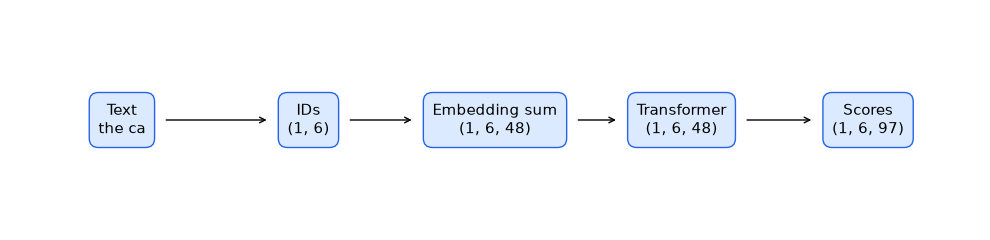

In [4]:
fig, ax = plt.subplots(figsize=(10, 2.5))
labels = ["Text\nthe ca", "IDs\n(1, 6)", "Embedding sum\n(1, 6, 48)",
          "Transformer\n(1, 6, 48)", "Scores\n(1, 6, 97)"]
boxes = []
for i, label in enumerate(labels):
    boxes.append(ax.text(i, 0, label, ha="center", va="center", fontsize=11,
                         bbox=dict(boxstyle="round,pad=0.6", fc="#dbeafe", ec="#2563eb")))
for i in range(len(boxes)-1):
    ax.annotate("", xy=(i+1, 0), xytext=(i, 0),
                arrowprops=dict(arrowstyle="->", patchA=boxes[i].get_bbox_patch(),
                                patchB=boxes[i+1].get_bbox_patch(), shrinkA=8, shrinkB=8))
ax.set_xlim(-0.6, 4.6); ax.set_ylim(-0.6, 0.6); ax.axis("off")
plt.tight_layout(); plt.show()

### Step C — select the last position, then normalize
There are six sets of scores because training predicts the next character at every position. To continue the complete prompt, use **only the final position's** 97 scores.

Softmax computes `exp(score) / sum(exp(all scores))`; PyTorch evaluates it in a numerically stable way. A probability here describes the model's next-character distribution, not the truth of a statement.

'r': 0.403
' ': 0.151
'i': 0.126
't': 0.102
'k': 0.068
'l': 0.053
'c': 0.042
'a': 0.024
Probability of 't': 0.102


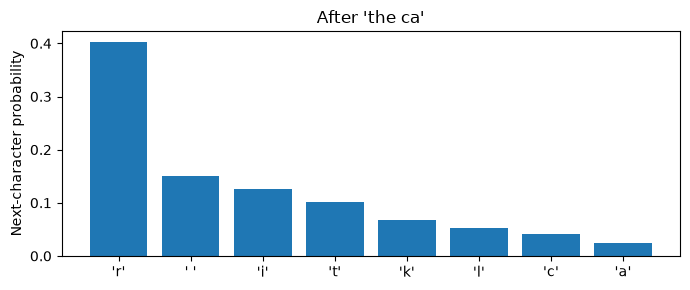

In [5]:
probabilities = logits[0, -1].softmax(-1)
values, indices = probabilities.topk(8)
for probability, index in zip(values, indices):
    print(f"{lab.ITOS[int(index)]!r}: {float(probability):.3f}")
print("Probability of 't':", round(float(probabilities[lab.STOI['t']]), 3))
assert torch.allclose(probabilities.sum(), torch.tensor(1.0))
plt.figure(figsize=(7, 3))
plt.bar([repr(lab.ITOS[int(i)]) for i in indices], values.tolist())
plt.ylabel("Next-character probability"); plt.title(f"After {prompt!r}")
plt.tight_layout(); plt.show()

### Step D — pick one token and repeat
**Greedy decoding** always chooses the highest-scoring token. Sampling can choose alternatives. **Temperature** rescales logits before softmax: lower temperatures concentrate the distribution. **Top-k** restricts sampling to the highest-scoring k tokens. Neither changes the learned weights.

In [6]:
torch.manual_seed(7)
print("Greedy: ", model.generate(prompt, max_new_tokens=60, greedy=True))
print("Sampled:", model.generate(prompt, max_new_tokens=60, temperature=0.9))
print("Trainable numbers:", sum(p.numel() for p in model.parameters()))

Greedy:  the car s sthe the stin.
the wararme walooooound.
the the the t r 
Sampled: the cainescheker ar.
t ar achid s skermer.
t ther.
t waies fliind 
Trainable numbers: 68353


### Check your understanding

Why is the final shape `(1, 6, 97)` rather than `(1, 6, 48)`? What does index `-1` select?

<details><summary>Suggested answer — try first</summary>

The output linear layer maps each 48-number hidden vector to 97 vocabulary scores. `logits[0, -1]` selects the last position of the first example; it does not select the most likely token.

</details>

### Your exercises
1. Change the prompt to `my friend `. Predict every tensor shape before running.
2. Set temperature to 0.5 and then 1.2. Compare the distributions, not only one sample.
3. Explain why sampling can produce a different character even when `t` has the highest probability.

**Completion criterion:** explain the entire path without saying that the model directly stores or manipulates words.

Reference: [PyTorch Embedding](https://docs.pytorch.org/docs/stable/generated/torch.nn.Embedding). Next: [02 — Understand learning](02_understand_learning.ipynb).